# Credit Default Prediction: Give Me Some Credit
**Goal:** predict whether a borrower will be 90+ days delinquent within two years (`SeriousDlqin2yrs`), then turn the model into an interpretable scorecard and explain it with SHAP.

**Data:** Kaggle *Give Me Some Credit*, `cs-training.csv` (150,000 borrowers, ~6.7% defaults). The competition test file has no labels, so everything is evaluated on a held-out 30% split of the training file.

**Plan:** audit → split first → leakage-free cleaning → EDA → models with cross-validation → evaluation beyond AUC (precision/recall/F1, PR curve, calibration) → WoE/IV scorecard and its validation → SHAP.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
os.makedirs('images', exist_ok=True)
SEED = 42
TARGET = 'SeriousDlqin2yrs'

## 1. Load data
Place `cs-training.csv` next to this notebook (or in a `data/` folder). Download it from the Kaggle competition page.

In [2]:
DATA = 'data/cs-training.csv' if os.path.exists('data/cs-training.csv') else 'cs-training.csv'
train_df = pd.read_csv(DATA)
print("Training:", train_df.shape)
display(train_df.head())

Training: (150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 2. Data audit
Descriptive checks only (nothing is fitted here): data types, ID column, duplicates, missing values.

In [3]:
print("Training data types:")
print(train_df.dtypes)
print("\nIdentifier analysis:")
print("Unique IDs:", train_df["Unnamed: 0"].nunique())
print("Minimum ID:", train_df["Unnamed: 0"].min())
print("Maximum ID:", train_df["Unnamed: 0"].max())

Training data types:
Unnamed: 0                                int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

Identifier analysis:
Unique IDs: 150000
Minimum ID: 1
Maximum ID: 150000


In [4]:
print("Duplicate rows:", train_df.duplicated().sum())
quality = pd.DataFrame({
    "Missing_Count": train_df.isnull().sum(),
    "Missing_Percentage": train_df.isnull().mean() * 100,
    "Unique_count": train_df.nunique()
})
display(quality.sort_values(by="Missing_Percentage", ascending=False))

Duplicate rows: 0


,Missing_Count,Missing_Percentage,Unique_count
MonthlyIncome,29731,19.820667,13594
NumberOfDependents,3924,2.616000,13
Unnamed: 0,0,0.000000,150000
SeriousDlqin2yrs,0,0.000000,2
age,0,0.000000,86
RevolvingUtilizationOfUnsecuredLines,0,0.000000,125728
DebtRatio,0,0.000000,114194
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000,16
NumberOfOpenCreditLinesAndLoans,0,0.000000,58
NumberOfTimes90DaysLate,0,0.000000,19


**Findings:** `MonthlyIncome` is ~19.8% missing and `NumberOfDependents` ~2.6%. `Unnamed: 0` is just a row ID (150,000 unique values), so it is dropped to avoid leaking row order into the model.

In [5]:
train_df = train_df.drop(columns=['Unnamed: 0'])

### Target balance, sentinel codes and outliers

In [6]:
# 1. target balance
print(train_df[TARGET].value_counts(normalize=True))

# 2. sentinel codes (96/98 in late-payment columns)
late_cols = ['NumberOfTime30-59DaysPastDueNotWorse',
             'NumberOfTimes90DaysLate',
             'NumberOfTime60-89DaysPastDueNotWorse']
masks = [train_df[c] >= 90 for c in late_cols]
for c, m in zip(late_cols, masks):
    print(c, int(m.sum()))
print("Same rows in all three columns:", bool((masks[0] == masks[1]).all() and (masks[1] == masks[2]).all()))
print("Codes found:", sorted(train_df.loc[masks[0], late_cols[0]].unique()))

# 3. outliers
display(train_df.describe(percentiles=[.01, .5, .99]).T)

SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64
NumberOfTime30-59DaysPastDueNotWorse 269
NumberOfTimes90DaysLate 269
NumberOfTime60-89DaysPastDueNotWorse 269
Same rows in all three columns: True
Codes found: [np.int64(96), np.int64(98)]


,count,mean,std,min,1%,50%,99%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.0,0.000000,1.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.0,0.154181,1.092956,50708.0
age,150000.0,52.295207,14.771866,0.0,24.0,52.000000,87.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.0,0.000000,4.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.0,0.366508,4979.040000,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,0.0,5400.000000,25000.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,0.0,8.000000,24.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.0,0.000000,3.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.0,1.000000,4.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.0,0.000000,2.000000,98.0


**Findings**
- **Imbalance:** only ~6.7% of borrowers default, so accuracy is useless; we use AUC, average precision, KS, precision/recall.
- **Sentinel codes:** the codes 96/98 appear in exactly the same 269 rows in all three late-payment columns, so flagging from one column misses nothing. They are not real counts. Whether these rows behave differently is checked against the **training labels only**, after the split (section 3).
- **Extreme values:** utilization up to 50,708 and a debt ratio up to 329,664 are data errors; one borrower has age 0.

## 3. Split first, then clean (no leakage)
The split happens **before preprocessing statistics are fitted**. All learned preprocessing parameters (medians, the debt-ratio cap) and all target-dependent checks are calculated using training data only. The section 2 audit above is purely descriptive (types, missing counts, value ranges, class balance) and fits nothing. The cleaner is applied to both splits and, because it sits inside each model's `Pipeline`, it is also re-fitted inside every cross-validation fold.

In [7]:
X, y = train_df.drop(columns=TARGET), train_df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print(X_tr.shape, X_te.shape, round(y_tr.mean(), 4), round(y_te.mean(), 4))

(105000, 10) (45000, 10) 0.0668 0.0668


### Sentinel check against the training labels only
The decision to flag the sentinel rows rather than drop them rests on this check, so it uses `y_tr` and never the test labels.

In [8]:
sent_tr = X_tr[late_cols[0]] >= 90
print("sentinel rows in the training split:", int(sent_tr.sum()))
print("default rate, sentinel rows :", round(y_tr[sent_tr].mean(), 3))
print("default rate, all others    :", round(y_tr[~sent_tr].mean(), 3))

sentinel rows in the training split: 182
default rate, sentinel rows : 0.544
default rate, all others    : 0.066


In [9]:
class CreditCleaner(BaseEstimator, TransformerMixin):
    """fit() learns age median, income median and the 99th-percentile debt ratio (training data only).
    transform() applies: sentinel flag + zeroing, age fix, missing-income flag, fills, caps, late_total."""

    def fit(self, X, y=None):
        age = X['age'].where(X['age'] >= 18)
        self.age_median_ = age.median()
        self.income_median_ = X['MonthlyIncome'].median()       # NaNs are skipped
        self.debt_cap_ = X['DebtRatio'].quantile(0.99)
        return self

    def transform(self, X):
        df = X.copy()
        # flag BEFORE overwriting the values the flag depends on
        df['sentinel_flag'] = (df[late_cols[0]] >= 90).astype(int)
        for c in late_cols:
            df[c] = df[c].where(df[c] < 90, 0)
        df['age'] = df['age'].where(df['age'] >= 18).fillna(self.age_median_)
        df['income_missing'] = df['MonthlyIncome'].isnull().astype(int)
        df['MonthlyIncome'] = df['MonthlyIncome'].fillna(self.income_median_)
        df['NumberOfDependents'] = df['NumberOfDependents'].fillna(0)
        df['RevolvingUtilizationOfUnsecuredLines'] = df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=2)
        df['DebtRatio'] = df['DebtRatio'].clip(upper=self.debt_cap_)
        df['late_total'] = df[late_cols].sum(axis=1)
        return df

**Why each step**
- **Sentinel flag:** keeps the 55%-default signal while removing the fake counts.
- **Missing flag + median:** missing income carries signal of its own; the median is not pulled by income outliers.
- **Caps:** utilization above 2 and extreme debt ratios are errors, capped so they don't distort the model.

In [10]:
cleaner = CreditCleaner().fit(X_tr)                      # statistics from the TRAINING split only
Xtr_c, Xte_c = cleaner.transform(X_tr), cleaner.transform(X_te)
print("learned on train -> age median:", cleaner.age_median_, "| income median:", cleaner.income_median_,
      "| debt cap:", round(cleaner.debt_cap_, 2))

# guards: flags must survive cleaning, and no nulls may remain
assert Xtr_c.sentinel_flag.sum() + Xte_c.sentinel_flag.sum() == 269
assert Xtr_c.income_missing.sum() + Xte_c.income_missing.sum() == 29731
assert Xtr_c.isnull().sum().sum() == 0 and Xte_c.isnull().sum().sum() == 0
print("flags OK:", int(Xtr_c.sentinel_flag.sum() + Xte_c.sentinel_flag.sum()), int(Xtr_c.income_missing.sum() + Xte_c.income_missing.sum()))
Xtr_c.describe().T

learned on train -> age median: 52.0 | income median: 5382.0 | debt cap: 4977.02
flags OK: 269 29731


,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,105000.0,0.324358,0.364898,0.0,0.029642,0.153553,0.560096,2.00
age,105000.0,52.277657,14.760952,21.0,41.000000,52.000000,63.000000,109.00
NumberOfTime30-59DaysPastDueNotWorse,105000.0,0.245905,0.698646,0.0,0.000000,0.000000,0.000000,13.00
DebtRatio,105000.0,316.574196,906.614479,0.0,0.175949,0.367554,0.861211,4977.02
MonthlyIncome,105000.0,6370.087133,10016.211160,0.0,3900.000000,5382.000000,7385.000000,1794060.00
NumberOfOpenCreditLinesAndLoans,105000.0,8.466371,5.149922,0.0,5.000000,8.000000,11.000000,58.00
NumberOfTimes90DaysLate,105000.0,0.090905,0.483810,0.0,0.000000,0.000000,0.000000,17.00
NumberRealEstateLoansOrLines,105000.0,1.019343,1.128383,0.0,0.000000,1.000000,2.000000,54.00
NumberOfTime60-89DaysPastDueNotWorse,105000.0,0.064705,0.328351,0.0,0.000000,0.000000,0.000000,11.00
NumberOfDependents,105000.0,0.738238,1.106077,0.0,0.000000,0.000000,1.000000,13.00


## 4. Exploratory analysis (training split): what drives default?

In [11]:
y_tr.groupby(pd.qcut(Xtr_c['RevolvingUtilizationOfUnsecuredLines'], 10, duplicates='drop'), observed=True).mean()

RevolvingUtilizationOfUnsecuredLines
(-0.001, 0.00283]    0.024571
(0.00283, 0.0189]    0.014095
(0.0189, 0.0432]     0.014476
(0.0432, 0.0827]     0.020095
(0.0827, 0.154]      0.023048
(0.154, 0.272]       0.032571
(0.272, 0.445]       0.052667
(0.445, 0.698]       0.089524
(0.698, 0.981]       0.164857
(0.981, 2.0]         0.232476
Name: SeriousDlqin2yrs, dtype: float64

In [12]:
print(y_tr.groupby(pd.qcut(Xtr_c['age'], 8), observed=True).mean())
print(y_tr.groupby(Xtr_c['late_total'].clip(upper=5), observed=True).agg(['count', 'mean']))
print(pd.concat([Xtr_c, y_tr], axis=1).corr()[TARGET].sort_values())

age
(20.999, 34.0]    0.109955
(34.0, 41.0]      0.093137
(41.0, 47.0]      0.082605
(47.0, 52.0]      0.076834
(52.0, 57.0]      0.064584
(57.0, 63.0]      0.047107
(63.0, 70.0]      0.028648
(70.0, 109.0]     0.023842
Name: SeriousDlqin2yrs, dtype: float64
            count      mean
late_total                 
0           83912  0.028601
1           12041  0.121086
2            4181  0.238221
3            2035  0.346437
4            1110  0.430631
5            1721  0.570017


age                                    -0.111761
NumberOfOpenCreditLinesAndLoans        -0.031493
income_missing                         -0.023866
MonthlyIncome                          -0.021114
DebtRatio                              -0.020679
NumberRealEstateLoansOrLines           -0.007765
NumberOfDependents                      0.045512
sentinel_flag                           0.079607
NumberOfTime60-89DaysPastDueNotWorse    0.267693
NumberOfTime30-59DaysPastDueNotWorse    0.267856
RevolvingUtilizationOfUnsecuredLines    0.281546
NumberOfTimes90DaysLate                 0.317734
late_total                              0.389303
SeriousDlqin2yrs                        1.000000
Name: SeriousDlqin2yrs, dtype: float64


**Findings**
- **Utilization:** default rate climbs from ~1.4% at low utilization to ~23% for borrowers at or over their limit, and it is non-linear (flat below ~0.15, steep above ~0.45).
- **Age:** default rate falls steadily from ~11% (under 34) to ~2% (over 70).
- **Past-due history:** the strongest signal, from ~3% with no past-due events to ~57% with five or more.

## 5. Models and cross-validation
Logistic regression (baseline), gradient boosting, and gradient boosting with isotonic probability calibration. The cleaner is **inside** each pipeline, so cross-validation never sees statistics from its validation fold.

In [13]:
gb_params = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1, random_state=SEED)
models = {
    'Logistic Regression': Pipeline([('clean', CreditCleaner()), ('scale', StandardScaler()),
                                     ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
    'Gradient Boosting': Pipeline([('clean', CreditCleaner()),
                                   ('model', HistGradientBoostingClassifier(**gb_params))]),
}
models['GB + isotonic calibration'] = CalibratedClassifierCV(
    Pipeline([('clean', CreditCleaner()), ('model', HistGradientBoostingClassifier(**gb_params))]),
    method='isotonic', cv=3)

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_rows = {}
for name, m in models.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv, n_jobs=-1, scoring={'auc': 'roc_auc', 'ap': 'average_precision'})
    cv_rows[name] = {'CV AUC': f"{r['test_auc'].mean():.4f} ± {r['test_auc'].std():.4f}",
                     'CV avg precision': f"{r['test_ap'].mean():.4f} ± {r['test_ap'].std():.4f}"}
pd.DataFrame(cv_rows).T

,CV AUC,CV avg precision
Logistic Regression,0.8553 ± 0.0065,0.3809 ± 0.0071
Gradient Boosting,0.8648 ± 0.0068,0.3989 ± 0.0069
GB + isotonic calibration,0.8652 ± 0.0066,0.3992 ± 0.0069


## 6. Evaluation beyond AUC
With only ~6.7% defaults, ROC-AUC alone can look good while precision is poor, so we also report average precision (PR-AUC), precision, recall, F1, a confusion matrix and calibration.

The decision threshold is chosen to maximise F1 on **out-of-fold training predictions**, never on the test set.

In [14]:
def ks_stat(y_true, p):
    y_true = np.asarray(y_true)
    return ks_2samp(p[y_true == 1], p[y_true == 0]).statistic

def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.argmax(f1))])

fitted, probs, thresholds = {}, {}, {}
for name, m in models.items():
    oof = cross_val_predict(m, X_tr, y_tr, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    thresholds[name] = best_f1_threshold(y_tr, oof)
    fitted[name] = m.fit(X_tr, y_tr)
    probs[name] = fitted[name].predict_proba(X_te)[:, 1]

rows = {}
for name, p_ in probs.items():
    pred = (p_ >= thresholds[name]).astype(int)
    rows[name] = {'AUC': roc_auc_score(y_te, p_), 'KS': ks_stat(y_te, p_),
                  'Avg precision': average_precision_score(y_te, p_), 'Brier': brier_score_loss(y_te, p_),
                  'Threshold': thresholds[name], 'Precision': precision_score(y_te, pred),
                  'Recall': recall_score(y_te, pred), 'F1': f1_score(y_te, pred)}
res = pd.DataFrame(rows).T.round(4)
display(res)
print("No-skill average precision = default rate =", round(y_te.mean(), 4))
for name, p_ in probs.items():
    tn, fp, fn, tp = confusion_matrix(y_te, (p_ >= thresholds[name]).astype(int)).ravel()
    print(f"{name}: TN={tn} FP={fp} FN={fn} TP={tp}")

lr, gb = fitted['Logistic Regression'], fitted['Gradient Boosting']
p, pg = probs['Logistic Regression'], probs['Gradient Boosting']

,AUC,KS,Avg precision,Brier,Threshold,Precision,Recall,F1
Logistic Regression,0.8567,0.5565,0.3819,0.1437,0.7242,0.3869,0.5146,0.4417
Gradient Boosting,0.8663,0.5772,0.4038,0.0487,0.2109,0.3994,0.5053,0.4461
GB + isotonic calibration,0.8668,0.5756,0.4018,0.0488,0.2297,0.4219,0.4711,0.4451


No-skill average precision = default rate = 0.0668
Logistic Regression: TN=39539 FP=2453 FN=1460 TP=1548
Gradient Boosting: TN=39706 FP=2286 FN=1488 TP=1520
GB + isotonic calibration: TN=40050 FP=1942 FN=1591 TP=1417


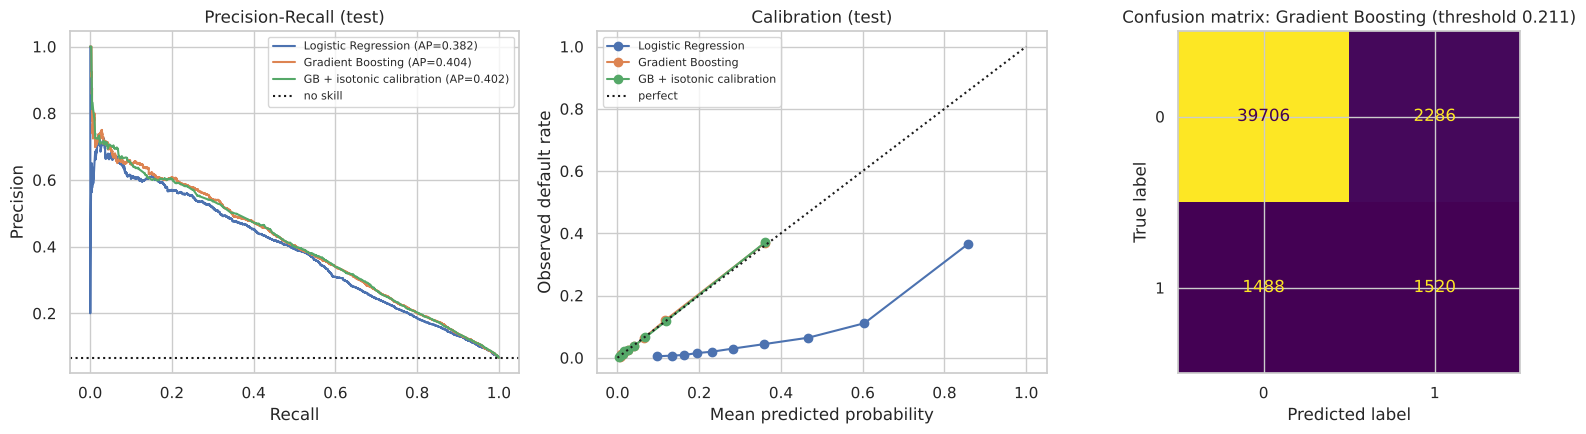

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for name, p_ in probs.items():                                   # precision-recall
    pr, rc, _ = precision_recall_curve(y_te, p_)
    ax[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_te, p_):.3f})")
ax[0].axhline(y_te.mean(), color='k', ls=':', label='no skill')
ax[0].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall (test)'); ax[0].legend(fontsize=8)

for name, p_ in probs.items():                                   # calibration
    frac, mean_pred = calibration_curve(y_te, p_, n_bins=10, strategy='quantile')
    ax[1].plot(mean_pred, frac, marker='o', label=name)
ax[1].plot([0, 1], [0, 1], 'k:', label='perfect')
ax[1].set(xlabel='Mean predicted probability', ylabel='Observed default rate', title='Calibration (test)'); ax[1].legend(fontsize=8)

ConfusionMatrixDisplay.from_predictions(y_te, (pg >= thresholds['Gradient Boosting']).astype(int), ax=ax[2], colorbar=False, values_format='d')
ax[2].set_title(f"Confusion matrix: Gradient Boosting (threshold {thresholds['Gradient Boosting']:.3f})")
plt.tight_layout(); plt.savefig('images/evaluation.png', dpi=150, bbox_inches='tight'); plt.show()

**Reading the evaluation**
- **Precision-recall:** average precision is far above the no-skill line (the default rate), so the model ranks defaulters well, not just on ROC-AUC.
- **Calibration:** gradient boosting sits on the diagonal (its probabilities are real default rates). Logistic regression with `class_weight='balanced'` over-predicts risk, so its raw probabilities must not be read as default rates; it is good for ranking only.
- **Trade-off:** at the F1-optimal threshold the model catches about half of the defaulters while roughly 40% of flagged borrowers actually default. A lender would move the threshold according to the cost of a missed default vs a rejected good borrower.

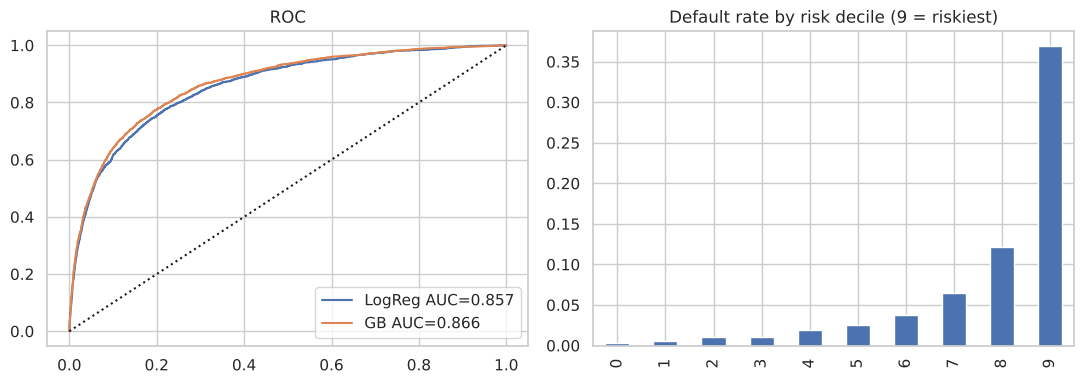

riskiest decile holds 0.553 of defaults; riskiest two deciles hold 0.733


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for pp, n in [(p, 'LogReg'), (pg, 'GB')]:
    f, t, _ = roc_curve(y_te, pp); ax[0].plot(f, t, label=f'{n} AUC={roc_auc_score(y_te, pp):.3f}')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].legend(); ax[0].set_title('ROC')
dec = pd.qcut(pg, 10, labels=False, duplicates='drop')
dr = y_te.groupby(dec).agg(['mean', 'sum'])
dr['mean'].plot.bar(ax=ax[1]); ax[1].set_title('Default rate by risk decile (9 = riskiest)')
plt.tight_layout(); plt.savefig('images/roc_deciles.png', dpi=150, bbox_inches='tight'); plt.show()
print("riskiest decile holds", round(dr['sum'].iloc[-1] / y_te.sum(), 3), "of defaults; riskiest two deciles hold", round(dr['sum'].iloc[-2:].sum() / y_te.sum(), 3))

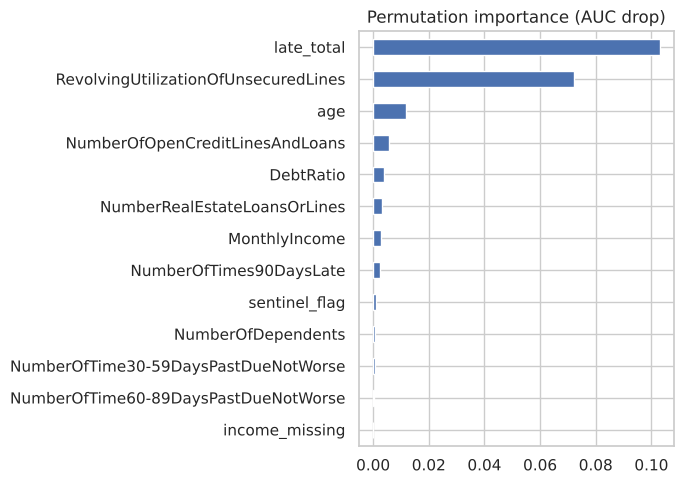

In [17]:
inner = gb.named_steps['model']
pi = permutation_importance(inner, Xte_c, y_te, scoring='roc_auc', n_repeats=3, random_state=0)
imp = pd.Series(pi.importances_mean, index=Xte_c.columns).sort_values()
imp.plot.barh(title='Permutation importance (AUC drop)', figsize=(7, 5))
plt.tight_layout(); plt.savefig('images/permutation_importance.png', dpi=150, bbox_inches='tight'); plt.show()

`late_total` and utilization dominate importance.

*Caveat:* permutation importance splits credit between correlated features, so the individual late-payment columns look weak only because `late_total` already carries their information.

## 7. WoE / IV scorecard
The classic bank approach: bin each variable, compute Weight of Evidence (`ln(%good / %bad)`) per bin and Information Value per variable, fit a logistic regression on WoE, and convert to points. Bins and WoE come from the **training split only**.

In [18]:
train = Xtr_c.copy(); train['y'] = y_tr.values

# bin edges: custom for count columns, quantile for continuous ones
EDGES = {'late_total': [-np.inf, 0, 1, 2, 4, np.inf],
         'sentinel_flag': [-np.inf, 0, np.inf],   # keeps the sentinel borrowers (~54% default in training) from being scored as clean
         'NumberRealEstateLoansOrLines': [-np.inf, 0, 1, 2, np.inf],
         'NumberOfDependents': [-np.inf, 0, 1, 2, np.inf]}
for c in ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']:
    q = np.unique(train[c].quantile(np.linspace(0, 1, 9)).values)
    q[0], q[-1] = -np.inf, np.inf
    EDGES[c] = q

def woe_table(df, col):
    b = pd.cut(df[col], bins=EDGES[col], include_lowest=True)
    t = df.groupby(b, observed=True)['y'].agg(bad='sum', n='count')
    t['good'] = t.n - t.bad
    g = (t.good + 0.5) / (t.good.sum() + 0.5*len(t))     # share of all goods in this bin
    bd = (t.bad + 0.5) / (t.bad.sum() + 0.5*len(t))      # share of all bads in this bin
    t['woe'] = np.log(g / bd)
    t['iv'] = (g - bd) * t.woe
    t['bad_rate'] = t.bad / t.n
    return t

tables = {c: woe_table(train, c) for c in EDGES}
iv = pd.Series({c: t.iv.sum() for c, t in tables.items()}).sort_values(ascending=False)
display(iv.round(4))
display(tables['RevolvingUtilizationOfUnsecuredLines'][['n', 'bad_rate', 'woe', 'iv']].round(3))

late_total                              1.3645
RevolvingUtilizationOfUnsecuredLines    1.0976
age                                     0.2413
MonthlyIncome                           0.0714
NumberOfOpenCreditLinesAndLoans         0.0686
DebtRatio                               0.0577
NumberRealEstateLoansOrLines            0.0569
sentinel_flag                           0.0376
NumberOfDependents                      0.0327
dtype: float64

,n,bad_rate,woe,iv
RevolvingUtilizationOfUnsecuredLines,,,,
"(-inf, 0.00618]",13125,0.022,1.142,0.102
"(0.00618, 0.0296]",13125,0.014,1.582,0.166
"(0.0296, 0.0705]",13125,0.017,1.411,0.140
"(0.0705, 0.154]",13125,0.023,1.108,0.097
"(0.154, 0.309]",13125,0.034,0.701,0.046
"(0.309, 0.56]",13125,0.065,0.027,0.000
"(0.56, 0.922]",13125,0.132,-0.756,0.099
"(0.922, inf]",13125,0.226,-1.404,0.447


**Why `sentinel_flag` is in the scorecard:** it passes the standard selection rule (IV above 0.02 on the training split, see the table above). It also matters in practice: the sentinel borrowers had their late counts zeroed, so without the flag the scorecard would score them as clean. The check after the model fit below shows this on the **training** data only.

IV rule of thumb: <0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, >0.5 very strong. `late_total` and utilization exceed 0.5 because past delinquency and credit usage are genuine predictors of future delinquency (not leakage).

In [19]:
# keep IV >= 0.02; late_total already covers the three separate late columns
selected = [c for c in iv.index if iv[c] >= 0.02]

def to_woe(df, cols):
    out = pd.DataFrame(index=df.index)
    for c in cols:
        b = pd.cut(df[c], bins=EDGES[c], include_lowest=True)
        out[c] = b.map(tables[c].woe).astype(float)
    return out

Xtr_w, Xte_w = to_woe(Xtr_c, selected), to_woe(Xte_c, selected)
lr_w = LogisticRegression(C=1.0, max_iter=1000).fit(Xtr_w, y_tr)

print(pd.Series(lr_w.coef_[0], index=selected).round(3))
print("intercept:", round(lr_w.intercept_[0], 3))
assert (lr_w.coef_[0] < 0).all(), "a positive coefficient means a bad bin or overlapping variables"

p_w = lr_w.predict_proba(Xte_w)[:, 1]
print("AUC:", roc_auc_score(y_te, p_w), " KS:", ks_stat(y_te, p_w), " Avg precision:", average_precision_score(y_te, p_w))

late_total                             -0.797
RevolvingUtilizationOfUnsecuredLines   -0.605
age                                    -0.388
MonthlyIncome                          -0.230
NumberOfOpenCreditLinesAndLoans        -0.075
DebtRatio                              -0.723
NumberRealEstateLoansOrLines           -0.518
sentinel_flag                          -0.873
NumberOfDependents                     -0.182
dtype: float64
intercept: -2.632
AUC: 0.8569209326345849  KS: 0.560973620101904  Avg precision: 0.37706163130774784


All coefficients are negative (higher WoE = safer ⇒ lower default log-odds), which the `assert` enforces.

In [20]:
# does the sentinel flag matter? compare predictions for the sentinel borrowers in the TRAINING split only
m_tr = (Xtr_c['sentinel_flag'] == 1).values
lr_noflag = LogisticRegression(C=1.0, max_iter=1000).fit(Xtr_w.drop(columns='sentinel_flag'), y_tr)
print("training sentinel rows       :", int(m_tr.sum()))
print("actual default rate          :", round(y_tr.values[m_tr].mean(), 3))
print("predicted WITHOUT the flag   :", round(lr_noflag.predict_proba(Xtr_w.drop(columns='sentinel_flag'))[:, 1][m_tr].mean(), 3))
print("predicted WITH the flag      :", round(lr_w.predict_proba(Xtr_w)[:, 1][m_tr].mean(), 3))

training sentinel rows       : 182
actual default rate          : 0.544
predicted WITHOUT the flag   : 0.102
predicted WITH the flag      : 0.545


### Points scorecard
Calibration: **600 points = 50:1 good:bad odds, +20 points = double the odds (PDO = 20)**. A borrower's score is the sum of the points of the bins they fall in.

In [21]:
PDO, BASE, ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE - factor * np.log(ODDS)
n = len(selected); b0 = lr_w.intercept_[0]
coef = dict(zip(selected, lr_w.coef_[0]))

card = []
for c in selected:
    t = tables[c].copy()
    t['points'] = (-(coef[c] * t.woe + b0 / n) * factor + offset / n).round(0)
    for b, r in t.iterrows():
        card.append((c, str(b), int(r.n), round(r.bad_rate, 3), int(r.points)))
card = pd.DataFrame(card, columns=['variable', 'bin', 'n', 'bad_rate', 'points'])
display(card)

,variable,bin,n,bad_rate,points
0,late_total,"(-inf, 0.0]",83912,0.029,83
1,late_total,"(0.0, 1.0]",12041,0.121,48
2,late_total,"(1.0, 2.0]",4181,0.238,29
3,late_total,"(2.0, 4.0]",3145,0.376,14
4,late_total,"(4.0, inf]",1721,0.570,-5
5,RevolvingUtilizationOfUnsecuredLines,"(-inf, 0.00618]",13125,0.022,83
6,RevolvingUtilizationOfUnsecuredLines,"(0.00618, 0.0296]",13125,0.014,90
7,RevolvingUtilizationOfUnsecuredLines,"(0.0296, 0.0705]",13125,0.017,87
8,RevolvingUtilizationOfUnsecuredLines,"(0.0705, 0.154]",13125,0.023,82
9,RevolvingUtilizationOfUnsecuredLines,"(0.154, 0.309]",13125,0.034,75


## 8. Scorecard validation
Checks: points agree with model log-odds (up to rounding), the score distribution separates good from bad, the default rate falls as score rises, **predicted probabilities match actual default rates per band**, and train/test AUC are close.

In [22]:
def score(df):
    pts = pd.Series(0.0, index=df.index)
    for c in selected:
        m = card[card.variable == c].set_index('bin').points.to_dict()
        b = pd.cut(df[c], bins=EDGES[c], include_lowest=True).astype(str)
        pts += b.map(m)
    return pts

s_te, s_tr = score(Xte_c), score(Xtr_c)

# 1. points must agree with the model's own log-odds (rounding only)
direct = offset - factor * lr_w.decision_function(Xte_w)
print("max difference:", round(float(np.abs(s_te - direct).max()), 1), "points")

# 2. overfitting check
print("train AUC:", round(roc_auc_score(y_tr, -s_tr), 4), " test AUC:", round(roc_auc_score(y_te, -s_te), 4))

# 3. default rate and predicted-vs-actual probability per score band
bands = pd.cut(s_te, [0, 500, 550, 600, 650, 1000])
pw = pd.Series(p_w, index=y_te.index)
bt = y_te.groupby(bands, observed=True).agg(borrowers='count', defaults='sum', actual_rate='mean')
bt['predicted_rate'] = pw.groupby(bands, observed=True).mean()
bt[['actual_rate', 'predicted_rate']] = (bt[['actual_rate', 'predicted_rate']] * 100).round(2)
display(bt)

max difference: 2.6 points
train AUC: 0.8558  test AUC: 0.857


,borrowers,defaults,actual_rate,predicted_rate
"(0, 500]",1700,861,50.65,52.40
"(500, 550]",5200,1072,20.62,19.66
"(550, 600]",18815,903,4.80,4.40
"(600, 650]",19285,172,0.89,1.26


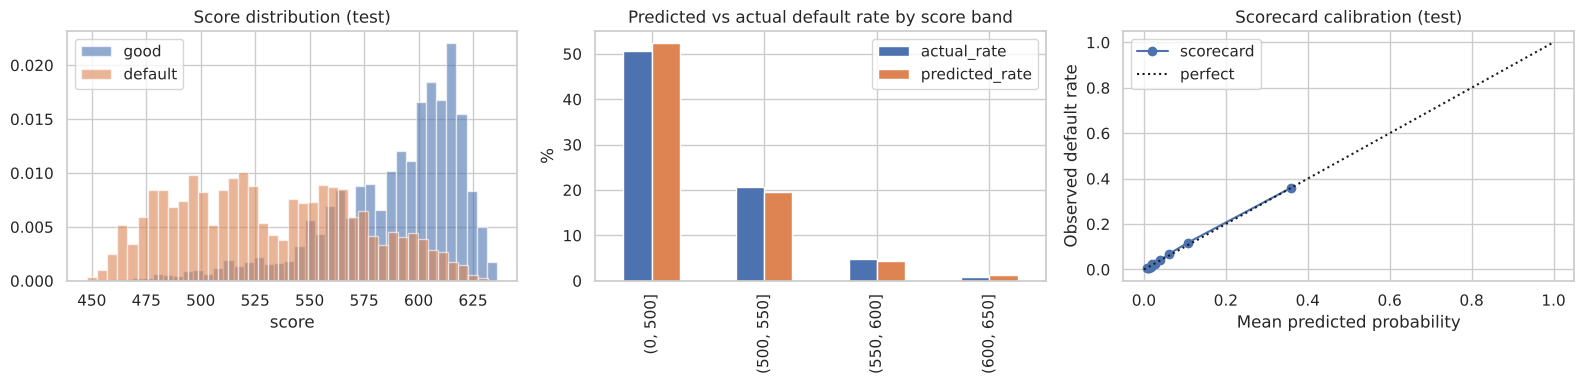

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(s_te[y_te == 0], bins=40, alpha=.6, density=True, label='good')
ax[0].hist(s_te[y_te == 1], bins=40, alpha=.6, density=True, label='default')
ax[0].set(title='Score distribution (test)', xlabel='score'); ax[0].legend()
bt[['actual_rate', 'predicted_rate']].plot.bar(ax=ax[1]); ax[1].set(title='Predicted vs actual default rate by score band', ylabel='%')
frac, mean_pred = calibration_curve(y_te, p_w, n_bins=10, strategy='quantile')
ax[2].plot(mean_pred, frac, marker='o', label='scorecard'); ax[2].plot([0, 1], [0, 1], 'k:', label='perfect')
ax[2].set(title='Scorecard calibration (test)', xlabel='Mean predicted probability', ylabel='Observed default rate'); ax[2].legend()
plt.tight_layout(); plt.savefig('images/scorecard_validation.png', dpi=150, bbox_inches='tight'); plt.show()

## 9. SHAP: explaining the gradient boosting model
Global view (which features push risk up or down) and one borrower's explanation. SHAP values are in log-odds; the waterfall shows how each feature moves one borrower from the average to their predicted risk. (SHAP is computed on the cleaned features that the model actually sees.)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


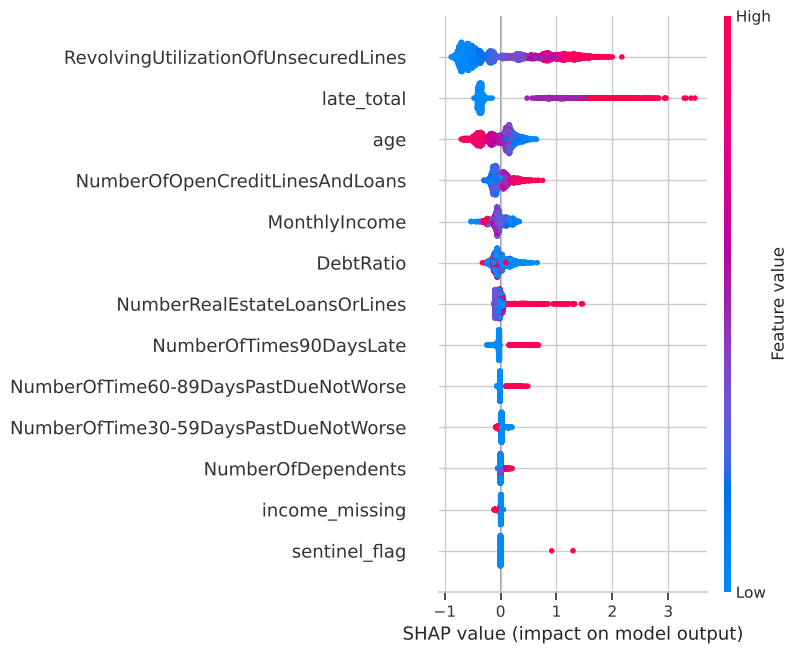

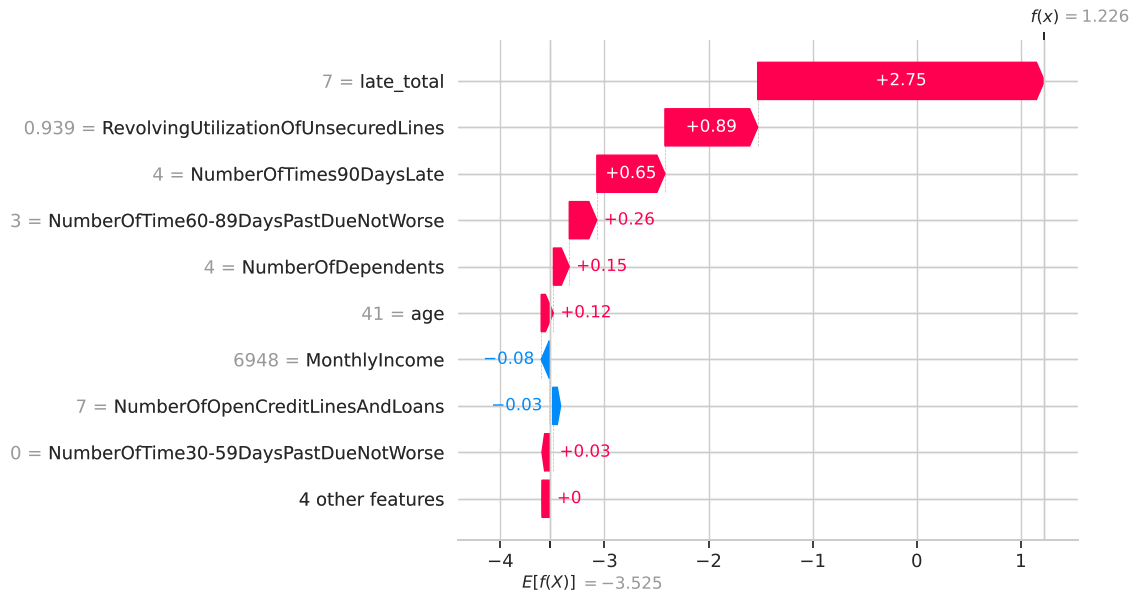

In [24]:
try:
    import shap
except ImportError:
    %pip install -q shap
    import shap

explainer = shap.TreeExplainer(inner)
sample = Xte_c.sample(3000, random_state=0)
sv = explainer(sample)

# global: which features push risk up or down
shap.summary_plot(sv.values, sample)

# one borrower: why this score
i = int(np.argmax(inner.predict_proba(sample)[:, 1]))     # riskiest borrower in the sample
shap.plots.waterfall(sv[i])

In [25]:
shap.summary_plot(sv.values, sample, show=False)
plt.savefig('images/shap_summary.png', dpi=150, bbox_inches='tight'); plt.close()

shap.plots.waterfall(sv[i], show=False)
plt.savefig('images/shap_waterfall.png', dpi=150, bbox_inches='tight'); plt.close()

**Reading SHAP:** in the summary plot, past-due history and utilization sit at the top, with high values (red) pushing risk up and older age pushing it down. The waterfall breaks one borrower's predicted risk into feature contributions. Overlapping late-payment columns share credit, so add their contributions together to read the total delinquency effect.

## 10. Limitations and next steps
- The data is from 2011 and anonymised, with no dates, so there is no out-of-time validation and no Population Stability Index (PSI) over time.
- Age is a model input; real lenders restrict it, and no fairness review was done.
- Evaluation uses one hold-out split plus 5-fold CV on the training part; hyper-parameter tuning was not done.
- Feature engineering was limited to `late_total` and the missing/sentinel flags; interaction features (e.g. age × delinquency) were not explored.
- Next: tuning, validated feature experiments, a Streamlit demo, and a SQL risk-analysis layer on the same data.